# Segmentation RFM : indicateurs et quatre segments K-means

Equipe 5, module Webmarketing et CRM (TDIA3). Sujet : segmentation RFM et prédiction du départ client.

**Périmètre de ce notebook (étape 2).** Calcul des indicateurs RFM à une date de référence explicite, préparation des variables, quatre segments K-means nommés avec une action marketing chacun. Le modèle de churn et les campagnes chiffrées viennent aux étapes suivantes et ne sont pas traités ici.

**Données.** Online Retail II, UCI Machine Learning Repository (Chen, D., 2012, https://doi.org/10.24432/C5CG6D, licence CC BY 4.0). Les fichiers `purchases.parquet` et `returns.parquet` sont produits par `python src/data_prep.py` (voir `docs/etape1_donnees.md`).

**Montants : ventes brutes hors retours.** `monetary_brut_gbp` est la somme de `Quantity x Price` des factures de vente. Les retours (factures `C*`) ne sont pas déduits : ce n'est pas un montant net. Les retours servent seulement à décrire les segments.

## 1. Paramètres

* **Date de référence `T = 2011-09-01`.** Seules les transactions datées strictement avant T sont utilisées. Les données s'arrêtent le 2011-12-09 : ce choix laisse 99 jours après T, donc la fenêtre de 90 jours (T, T+90 j] du futur calcul du churn sera entièrement observable. Ce choix est à valider par l'équipe.
* **k = 4**, imposé par le sujet. La section 5 examine ce que ce choix coûte.
* **Graine aléatoire 42**, pour un résultat identique à chaque exécution.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_prep
import rfm as rfmlib

REFERENCE_DATE = pd.Timestamp("2011-09-01")
K = 4
SEED = 42
OUT_SEGMENTS = ROOT / "data" / "processed" / "rfm_segments_2011-09-01.parquet"
OUT_SUMMARY = ROOT / "reports" / "rfm_segments_summary.csv"
OUT_FIGS = ROOT / "reports" / "figures"
OUT_FIGS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 30)
print("Date de référence :", REFERENCE_DATE, "| k =", K, "| graine =", SEED)

Date de référence : 2011-09-01 00:00:00 | k = 4 | graine = 42


## 2. Chargement et contrôle de cohérence des données

On vérifie d'abord que les fichiers présents correspondent à la source épinglée et au rapport de l'étape 1 (empreintes SHA-256 du zip, de l'Excel et des trois fichiers parquet). Le notebook s'arrête si un contrôle échoue.

In [2]:
assert data_prep.verify() == 0, "Les données ne correspondent pas au rapport : relancer python src/data_prep.py"
purchases = pd.read_parquet(ROOT / "data" / "processed" / "purchases.parquet")
returns = pd.read_parquet(ROOT / "data" / "processed" / "returns.parquet")
print(f"\nachats : {len(purchases):,} lignes, {purchases.customer_id.nunique():,} clients, "
      f"{purchases.InvoiceDate.min():%Y-%m-%d} -> {purchases.InvoiceDate.max():%Y-%m-%d}")
print(f"retours : {len(returns):,} lignes (non déduits des achats)")

OK    zip = valeur epinglee  (reference : 572E36277C2390FBFDE10664750731E0A86F55E33470D91919085F0408E67BFB)
OK    zip = rapport  (reference : 572E36277C2390FBFDE10664750731E0A86F55E33470D91919085F0408E67BFB)
OK    zip = manifeste  (reference : 572E36277C2390FBFDE10664750731E0A86F55E33470D91919085F0408E67BFB)
OK    xlsx = contenu du zip  (reference : BCBE73B35F5B7BABF197FB0CB983A11F5D9FF929078D4AA53D171B1F2DF2E980)
OK    xlsx = rapport  (reference : BCBE73B35F5B7BABF197FB0CB983A11F5D9FF929078D4AA53D171B1F2DF2E980)
OK    xlsx = manifeste  (reference : BCBE73B35F5B7BABF197FB0CB983A11F5D9FF929078D4AA53D171B1F2DF2E980)
OK    raw.parquet = manifeste  (reference : 121686E90C9CEEBDA6F38B802C0D2118887053AB2698ABD5BAC97F68D44F00CE)
OK    schema du cache a jour  (reference : 2)
OK    raw.parquet : lignes = rapport  (reference : 1067371)
OK    purchases.parquet : lignes = rapport  (reference : 788127)
OK    returns.parquet : lignes = rapport  (reference : 17641)
OK    raw.parquet : SHA-256 = rappo


achats : 788,127 lignes, 5,852 clients, 2009-12-01 -> 2011-12-09
retours : 17,641 lignes (non déduits des achats)


## 3. Calcul RFM à la date de référence

Pour chaque client ayant au moins un achat avant T :

| Indicateur | Définition |
|---|---|
| Récence `recency_days` | jours entiers écoulés entre le dernier achat et T (0 = achat la veille de T) |
| Fréquence `frequency` | nombre de factures de vente distinctes avant T |
| Montant `monetary_brut_gbp` | somme des ventes brutes (GBP) avant T, **retours non déduits** |

La récence est mesurée par rapport à T, jamais par rapport à la dernière date du jeu de données.

In [3]:
rfm = rfmlib.build_rfm(purchases, REFERENCE_DATE)
print(f"{len(rfm):,} clients actifs avant T")
rfm[rfmlib.RFM_COLUMNS].describe(percentiles=[.5, .9, .99]).round(1)

5,224 clients actifs avant T


,recency_days,frequency,monetary_brut_gbp
count,5224.0,5224.0,5224.0
mean,203.1,5.7,2588.5
std,170.8,11.1,11950.7
min,0.0,1.0,1.6
50%,160.0,3.0,779.1
90%,464.0,12.0,4888.2
99%,629.8,41.8,26335.7
max,638.0,278.0,451867.0


### Test d'absence de fuite

Trois contrôles montrent que le calcul n'utilise rien d'après T :

1. le résultat est identique si on retire du tableau toutes les lignes datées de T ou après ;
2. il est identique si on **falsifie** les lignes datées de T ou après (montants multipliés par 1 000, identifiants décalés) ;
3. le dernier achat pris en compte est antérieur à T.

In [4]:
before_T = purchases[purchases.InvoiceDate < REFERENCE_DATE]
assert rfmlib.build_rfm(before_T, REFERENCE_DATE).equals(rfm), "test 1 échoué"

tampered = purchases.copy()
future = tampered.InvoiceDate >= REFERENCE_DATE
tampered.loc[future, "montant_brut_gbp"] *= 1000
tampered.loc[future, "customer_id"] += 1
assert rfmlib.build_rfm(tampered, REFERENCE_DATE).equals(rfm), "test 2 échoué"

assert rfm.last_purchase.max() < REFERENCE_DATE, "test 3 échoué"

after = purchases[future]
only_after = set(after.customer_id) - set(rfm.index)
print("Tests 1, 2 et 3 réussis.")
print(f"Dernier achat pris en compte : {rfm.last_purchase.max()}")
print(f"{after.customer_id.nunique():,} clients achètent à partir de T ; "
      f"{len(only_after):,} d'entre eux n'avaient encore jamais acheté et n'ont donc pas de segment à T.")

Tests 1, 2 et 3 réussis.
Dernier achat pris en compte : 2011-08-31 17:16:00
2,967 clients achètent à partir de T ; 628 d'entre eux n'avaient encore jamais acheté et n'ont donc pas de segment à T.


## 4. Préparation des variables

Les trois indicateurs sont très asymétriques (quelques gros clients tirent la moyenne). K-means mesure des distances euclidiennes : sans transformation, le montant dominerait la récence et la fréquence, et quelques clients extrêmes formeraient leurs propres groupes.

1. **`log(1 + x)`** sur R, F et M. Les valeurs sont positives : R vaut au minimum 0, F au minimum 1, M est strictement positif.
2. **Standardisation** (moyenne 0, écart type 1) pour que les trois variables pèsent autant.

Les clients à très gros montant ne sont pas supprimés : ils sont de vrais clients, et le logarithme limite leur influence.

Le `StandardScaler` et le K-means sont ajustés ici sur la population de T. Au moment du modèle de churn, ils seront ajustés sur la période d'entraînement seulement, puis appliqués à la période de test.

,asymétrie avant,asymétrie après log
recency_days,0.69,-0.98
frequency,10.43,1.06
monetary_brut_gbp,24.04,0.27


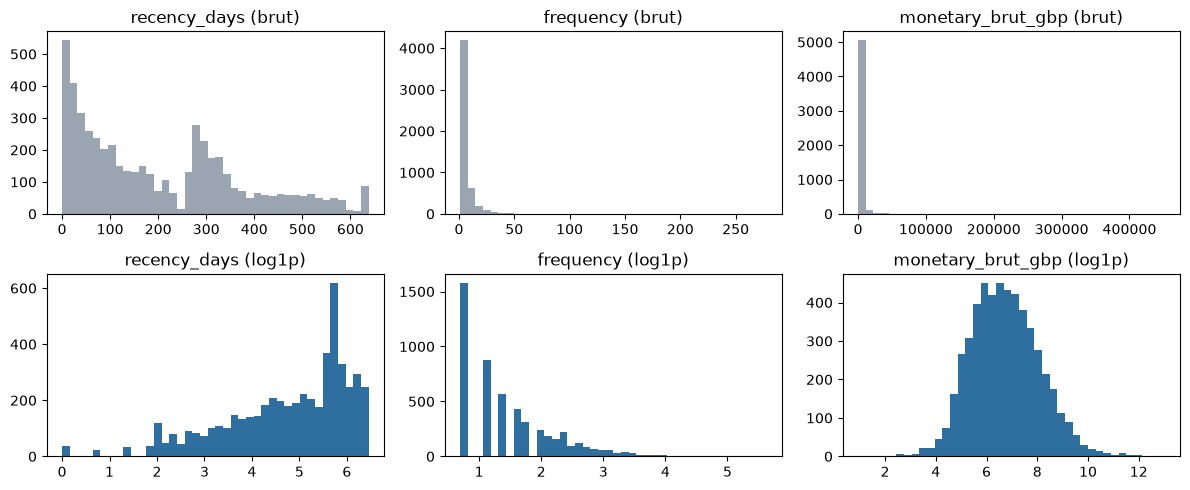

In [5]:
logged = rfmlib.log_features(rfm)
skew = pd.DataFrame({"asymétrie avant": rfm[rfmlib.RFM_COLUMNS].skew(), "asymétrie après log": logged.skew()}).round(2)
display(skew)

scaler = StandardScaler().fit(logged)
X = scaler.transform(logged)

fig, axes = plt.subplots(2, 3, figsize=(12, 5))
for j, col in enumerate(rfmlib.RFM_COLUMNS):
    axes[0, j].hist(rfm[col], bins=40, color="#9aa5b1"); axes[0, j].set_title(f"{col} (brut)")
    axes[1, j].hist(logged[col], bins=40, color="#2f6f9f"); axes[1, j].set_title(f"{col} (log1p)")
plt.tight_layout(); fig.savefig(OUT_FIGS / "rfm_distributions.png", dpi=120); plt.show()

## 5. Quatre segments K-means

### Quatre est-il un bon choix ?

Le sujet impose quatre segments. On regarde malgré tout l'inertie et le coefficient de silhouette pour k de 2 à 8, et la stabilité du résultat selon la graine.

,inertie,silhouette
k,,
2,7665,0.454
3,5699,0.357
4,4473,0.379
5,3756,0.333
6,3314,0.325
7,2988,0.292
8,2731,0.285


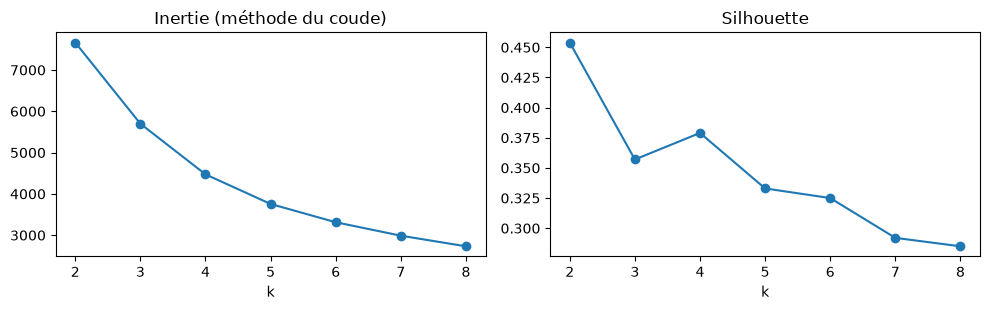

Stabilité selon la graine (10 graines) : indice de Rand ajusté min = 0.977, moyenne = 0.988


In [6]:
rows = []
for k in range(2, 9):
    km_k = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    rows.append({"k": k, "inertie": round(km_k.inertia_), "silhouette": round(silhouette_score(X, km_k.labels_), 3)})
selection = pd.DataFrame(rows).set_index("k")
display(selection)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(selection.index, selection.inertie, "o-"); ax[0].set_title("Inertie (méthode du coude)"); ax[0].set_xlabel("k")
ax[1].plot(selection.index, selection.silhouette, "o-"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); fig.savefig(OUT_FIGS / "rfm_choix_k.png", dpi=120); plt.show()

km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(X)
aris = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=20, random_state=s).fit(X).labels_) for s in range(10)]
print(f"Stabilité selon la graine (10 graines) : indice de Rand ajusté min = {min(aris):.3f}, moyenne = {np.mean(aris):.3f}")

**Lecture.** La silhouette de k = 4 est inférieure à celle de k = 2 : les clients forment un nuage continu plus qu'un ensemble de groupes nets. Quatre segments restent utiles en marketing (une action par segment), mais ils découpent un continuum et leurs frontières sont conventionnelles. En revanche, le découpage est stable : changer la graine ne modifie presque pas les affectations (indice de Rand ajusté proche de 1).

### Profil des segments

In [7]:
rfm["cluster"] = km.labels_
rfm["tenure_days"] = (REFERENCE_DATE - rfm.first_purchase).dt.days
rfm = rfm.join(rfmlib.returns_summary_before(returns, REFERENCE_DATE)).fillna({"return_lines": 0, "returns_gbp": 0})

g = rfm.groupby("cluster")
profile = pd.DataFrame({
    "clients": g.size(),
    "R_médiane_j": g.recency_days.median(),
    "F_médiane": g.frequency.median(),
    "M_médiane_gbp": g.monetary_brut_gbp.median(),
    "R_moyenne_j": g.recency_days.mean(),
    "F_moyenne": g.frequency.mean(),
    "M_moyenne_gbp": g.monetary_brut_gbp.mean(),
    "ventes_brutes_gbp": g.monetary_brut_gbp.sum(),
    "ancienneté_médiane_j": g.tenure_days.median(),
    "part_nouveaux_90j": g.tenure_days.agg(lambda s: (s <= 90).mean()),
    "part_une_seule_facture": g.frequency.agg(lambda s: (s == 1).mean()),
    "part_avec_retour": g.return_lines.agg(lambda s: (s > 0).mean()),
})
profile["part_clients"] = profile.clients / profile.clients.sum()
profile["part_ventes_brutes"] = profile.ventes_brutes_gbp / profile.ventes_brutes_gbp.sum()

names = rfmlib.name_segments(rfm)
profile.insert(0, "segment", profile.index.map(names))
order = ["Champions", "Réguliers à risque", "Récents à développer", "Endormis"]
profile = profile.set_index("segment").loc[order]
fmt = {"M_médiane_gbp": "{:,.0f}", "M_moyenne_gbp": "{:,.0f}", "ventes_brutes_gbp": "{:,.0f}", "R_moyenne_j": "{:.0f}", "F_moyenne": "{:.1f}",
       "part_nouveaux_90j": "{:.0%}", "part_une_seule_facture": "{:.0%}", "part_avec_retour": "{:.0%}", "part_clients": "{:.1%}", "part_ventes_brutes": "{:.1%}"}
display(profile.style.format(fmt))

,clients,R_médiane_j,F_médiane,M_médiane_gbp,R_moyenne_j,F_moyenne,M_moyenne_gbp,ventes_brutes_gbp,ancienneté_médiane_j,part_nouveaux_90j,part_une_seule_facture,part_avec_retour,part_clients,part_ventes_brutes
segment,,,,,,,,,,,,,,
Champions,851,21.000000,14.000000,"5,288",32,19.4,"10,671","9,081,055",588.000000,0%,0%,83%,16.3%,67.2%
Réguliers à risque,1530,167.500000,5.000000,"1,484",198,5.2,"2,037","3,115,928",537.000000,0%,1%,54%,29.3%,23.0%
Récents à développer,753,30.000000,3.000000,644,35,2.9,809,"609,305",180.000000,33%,22%,30%,14.4%,4.5%
Endormis,2090,318.000000,1.000000,294,337,1.4,343,"716,269",374.000000,3%,67%,18%,40.0%,5.3%


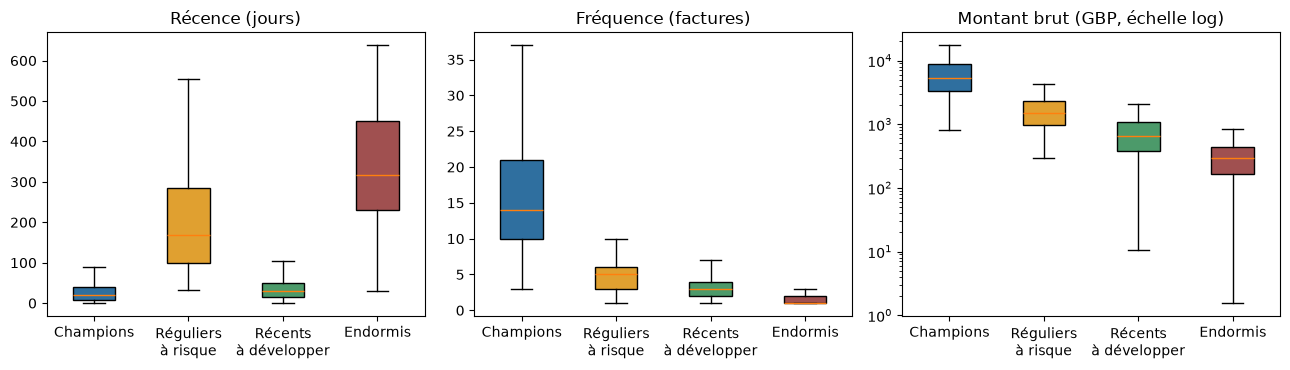

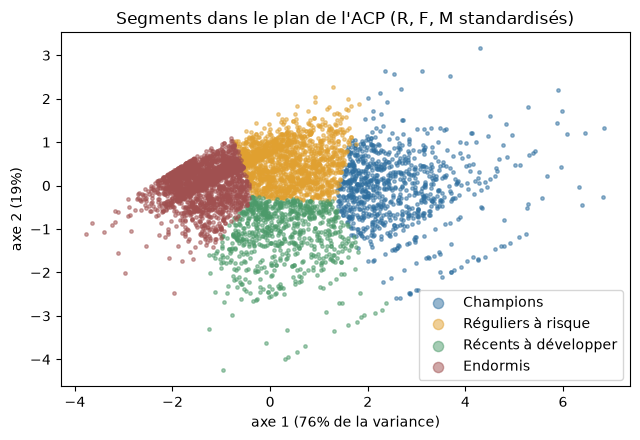

In [8]:
rfm["segment"] = rfm.cluster.map(names)
seg_colors = {"Champions": "#2f6f9f", "Réguliers à risque": "#e0a030", "Récents à développer": "#4c9a6a", "Endormis": "#a05050"}

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, title in zip(axes, rfmlib.RFM_COLUMNS, ["Récence (jours)", "Fréquence (factures)", "Montant brut (GBP, échelle log)"]):
    data = [rfm.loc[rfm.segment == s, col] for s in order]
    bp = ax.boxplot(data, tick_labels=[s.replace(" ", "\n", 1) for s in order], showfliers=False, patch_artist=True)
    for patch, s in zip(bp["boxes"], order): patch.set_facecolor(seg_colors[s])
    ax.set_title(title)
    if col == "monetary_brut_gbp": ax.set_yscale("log")
plt.tight_layout(); fig.savefig(OUT_FIGS / "rfm_profils_segments.png", dpi=120); plt.show()

pcs = PCA(n_components=2, random_state=SEED).fit(X)
Z = pcs.transform(X)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for s in order:
    m = (rfm.segment == s).to_numpy()
    ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=.5, label=s, color=seg_colors[s])
ax.set_xlabel(f"axe 1 ({pcs.explained_variance_ratio_[0]:.0%} de la variance)"); ax.set_ylabel(f"axe 2 ({pcs.explained_variance_ratio_[1]:.0%})")
ax.legend(markerscale=3); ax.set_title("Segments dans le plan de l'ACP (R, F, M standardisés)")
plt.tight_layout(); fig.savefig(OUT_FIGS / "rfm_acp_segments.png", dpi=120); plt.show()

## 6. Noms et actions marketing

Les noms sont attribués par une règle qui lit les médianes (fonction `name_segments` de `src/rfm.py`) : Champions = médiane de montant la plus haute ; Récents à développer = récence la plus basse parmi les trois autres ; Endormis = récence la plus haute parmi les deux restants ; le dernier est Réguliers à risque. La règle ne dépend pas de la numérotation des clusters. Elle est calibrée sur ce jeu et cette date : pour une autre date, relire le profil avant de réutiliser les noms.

| Segment | Profil observé à T (médianes) | Action marketing proposée |
|---|---|---|
| **Champions** | achat récent (≈ 21 j), 14 factures, ≈ 5 300 GBP. Ancienneté élevée. Environ 16 % des clients et 67 % des ventes brutes | **Fidéliser sans brader** : accès anticipé aux nouveautés, service dédié, offre de volume plutôt que remise générale. Surveiller toute hausse de récence : c'est le signal d'alerte le plus coûteux. |
| **Réguliers à risque** | dernier achat il y a ≈ 168 j, 5 factures, ≈ 1 480 GBP. Clients installés mais qui espacent leurs achats | **Relancer avant qu'ils ne dorment** : e-mail personnalisé qui rappelle leurs catégories habituelles, offre limitée dans le temps, suivi du taux de retour à l'achat. |
| **Récents à développer** | achat récent (≈ 30 j), 3 factures, ≈ 640 GBP. Ancienneté médiane ≈ 180 j, un tiers a moins de 90 j | **Encourager le prochain achat** : séquence de bienvenue et recommandations de produits complémentaires pour obtenir les 2e et 3e commandes, puis intégration au parcours fidélité. |
| **Endormis** | dernier achat il y a ≈ 318 j, 1 facture pour les deux tiers, ≈ 290 GBP | **Réactiver à coût plafonné** : une seule campagne de retour, offre simple et limitée. Sans réponse, les retirer des envois pour limiter le coût et la fatigue. |

Les valeurs du tableau sont celles de la sortie de la section 5 (médianes). Elles ne valent que pour T = 2011-09-01.

## 7. Limites des données et de la segmentation

* **Ventes brutes, pas nettes.** Les retours ne sont pas déduits. Cela peut surévaluer certains clients : le contrôle ci-dessous les liste.
* **Un seul détaillant britannique, beaucoup de grossistes** (UK : environ 90 % des lignes). Les comportements ne sont pas transposables tels quels à une entreprise marocaine.
* **Clients sans identifiant exclus** (22,77 % des lignes brutes). Ils sont probablement des acheteurs occasionnels ou des ventes en ligne sans compte : les segments décrivent surtout les clients identifiés.
* **Période courte et saisonnière.** Deux ans, pic de septembre à novembre. La récence à T = 1er septembre n'a pas le même sens qu'en décembre.
* **Clients arrivés après T absents.** Ils n'ont pas de segment à T (voir le test d'absence de fuite) : un modèle fondé sur ces segments ne les couvre pas.
* **Le K-means découpe un continuum.** Silhouette modeste, frontières conventionnelles.
* **Pas de marge, de canal ni de coût.** Le montant est un chiffre d'affaires, pas un profit.
* **Segments descriptifs, non causaux.** Ils ne disent pas pourquoi un client est dans un segment ni quel effet aurait une action.

In [9]:
over = rfm[(-rfm.returns_gbp) > 0.5 * rfm.monetary_brut_gbp]
print(f"{len(over)} clients ont des retours avant T supérieurs à la moitié de leurs ventes brutes "
      f"({len(over) / len(rfm):.2%} des clients).")
print("Répartition par segment :", over.segment.value_counts().to_dict())
display(rfm.sort_values("returns_gbp").head(5)[["segment", "monetary_brut_gbp", "returns_gbp"]].round(0))

33 clients ont des retours avant T supérieurs à la moitié de leurs ventes brutes (0.63% des clients).
Répartition par segment : {'Endormis': 24, 'Réguliers à risque': 7, 'Récents à développer': 2}


,segment,monetary_brut_gbp,returns_gbp
customer_id,,,
12346,Réguliers à risque,77353.0,-77184.0
15749,Réguliers à risque,44534.0,-22998.0
12931,Champions,82822.0,-19750.0
14277,Réguliers à risque,14275.0,-12570.0
14911,Champions,204805.0,-12362.0


## 8. Export

Le fichier client par client et le tableau de profil sont écrits pour les étapes suivantes. Le tableau de profil est versionné ; les données clients restent dans `data/` (non versionné).

In [10]:
out = rfm.reset_index()[["customer_id", "recency_days", "frequency", "monetary_brut_gbp", "first_purchase", "last_purchase", "cluster", "segment"]]
out.insert(1, "reference_date", REFERENCE_DATE)
out = out.sort_values("customer_id").reset_index(drop=True)
out.to_parquet(OUT_SEGMENTS, index=False)

summary = profile.reset_index().round(4)
summary.insert(1, "reference_date", REFERENCE_DATE.date().isoformat())
summary.to_csv(OUT_SUMMARY, index=False, encoding="utf-8")
print("Écrit :", OUT_SEGMENTS.relative_to(ROOT), "et", OUT_SUMMARY.relative_to(ROOT))
print(f"Contrôle : {len(out):,} clients, {out.segment.nunique()} segments, "
      f"valeurs manquantes = {int(out.isna().sum().sum())}")

Écrit : data\processed\rfm_segments_2011-09-01.parquet et reports\rfm_segments_summary.csv
Contrôle : 5,224 clients, 4 segments, valeurs manquantes = 0
